# 01. MLB 2025: 피타고라스 기대 승률과 실제 승률

강의(University of Michigan, *Foundations of Sports Analytics*) 1주차 방법을 **2025 MLB 정규시즌 전체 경기(2,430경기)**에 적용했다. 팀별로 홈·원정 성적을 합쳐 득점·실점·승률을 구하고, 기대 승률(지수 2)과 실제 승률의 관계를 회귀분석으로 확인한다.

In [1]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
MLB = pd.read_excel('../data/mlb-2025-asplayed.xlsx',sheet_name='As-Played Schedule')
print(MLB.columns.tolist())

['Date', 'Start Time (Sask)', 'Start Time (EDT)', 'Away', 'Away Score', 'Home', 'Home Score', 'Status', 'Away Starter', 'Home Starter', 'Winner', 'Loser', 'Save']


In [3]:
MLB

,Date,Start Time (Sask),Start Time (EDT),Away,Away Score,Home,Home Score,Status,Away Starter,Home Starter,Winner,Loser,Save
0,2025-03-18,4:10 AM,6:10 AM,Los Angeles Dodgers,4,Chicago Cubs,1,Final,Yoshinobu Yamamoto,Shota Imanaga,Yoshinobu Yamamoto,Ben Brown,Tanner Scott
1,2025-03-19,4:10 AM,6:10 AM,Los Angeles Dodgers,6,Chicago Cubs,3,Final,Roki Sasaki,Justin Steele,Landon Knack,Justin Steele,Alex Vesia
2,2025-03-27,1:05 PM,3:05 PM,Milwaukee Brewers,2,New York Yankees,4,Final,Freddy Peralta,Carlos Rodón,Carlos Rodón,Freddy Peralta,Devin Williams
3,2025-03-27,1:07 PM,3:07 PM,Baltimore Orioles,12,Toronto Blue Jays,2,Final,Zach Eflin,José Berríos,Zach Eflin,José Berríos,NaN
4,2025-03-27,2:05 PM,4:05 PM,Boston Red Sox,5,Texas Rangers,2,Final,Garrett Crochet,Nathan Eovaldi,Aroldis Chapman,Luke Jackson,Justin Slaten
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2425,2025-09-28,1:10 PM,3:10 PM,Texas Rangers,8,Cleveland Guardians,9,Final,Patrick Corbin,Logan Allen,Zak Kent,Jose Corniell,NaN
2426,2025-09-28,1:10 PM,3:10 PM,New York Mets,0,Miami Marlins,4,Final,Sean Manaea,Edward Cabrera,Edward Cabrera,Brooks Raley,NaN
2427,2025-09-28,1:10 PM,3:10 PM,Cincinnati Reds,2,Milwaukee Brewers,4,Final,Brady Singer,Freddy Peralta,Trevor Megill,Brady Singer,Abner Uribe
2428,2025-09-28,1:15 PM,3:15 PM,Pittsburgh Pirates,1,Atlanta Braves,4,Final,Johan Oviedo,Charlie Morton,Chris Sale,Johan Oviedo,Raisel Iglesias


In [4]:
MLB18 = MLB[['Away','Home','Away Score','Home Score','Date']]
MLB18 = MLB18.rename(columns={'Away':'Visiting Team','Home':'Home Team','Away Score':'VisR','Home Score':'HomR'})
MLB18

,Visiting Team,Home Team,VisR,HomR,Date
0,Los Angeles Dodgers,Chicago Cubs,4,1,2025-03-18
1,Los Angeles Dodgers,Chicago Cubs,6,3,2025-03-19
2,Milwaukee Brewers,New York Yankees,2,4,2025-03-27
3,Baltimore Orioles,Toronto Blue Jays,12,2,2025-03-27
4,Boston Red Sox,Texas Rangers,5,2,2025-03-27
...,...,...,...,...,...
2425,Texas Rangers,Cleveland Guardians,8,9,2025-09-28
2426,New York Mets,Miami Marlins,0,4,2025-09-28
2427,Cincinnati Reds,Milwaukee Brewers,2,4,2025-09-28
2428,Pittsburgh Pirates,Atlanta Braves,1,4,2025-09-28


In [5]:
MLB18['hwin'] = np.where(MLB18['HomR']>MLB18['VisR'],1,0)
MLB18['awin'] = np.where(MLB18['HomR']<MLB18['VisR'],1,0)
MLB18['count'] = 1
MLB18

,Visiting Team,Home Team,VisR,HomR,Date,hwin,awin,count
0,Los Angeles Dodgers,Chicago Cubs,4,1,2025-03-18,0,1,1
1,Los Angeles Dodgers,Chicago Cubs,6,3,2025-03-19,0,1,1
2,Milwaukee Brewers,New York Yankees,2,4,2025-03-27,1,0,1
3,Baltimore Orioles,Toronto Blue Jays,12,2,2025-03-27,0,1,1
4,Boston Red Sox,Texas Rangers,5,2,2025-03-27,0,1,1
...,...,...,...,...,...,...,...,...
2425,Texas Rangers,Cleveland Guardians,8,9,2025-09-28,1,0,1
2426,New York Mets,Miami Marlins,0,4,2025-09-28,1,0,1
2427,Cincinnati Reds,Milwaukee Brewers,2,4,2025-09-28,1,0,1
2428,Pittsburgh Pirates,Atlanta Braves,1,4,2025-09-28,1,0,1


In [6]:
MLBhome = MLB18.groupby('Home Team')[['hwin','HomR','VisR','count']].sum().reset_index()
MLBhome = MLBhome.rename(columns={'Home Team':'team','VisR':'VisRh','HomR':'HomRh','count':'Gh'})
MLBhome

,team,hwin,HomRh,VisRh,Gh
0,Arizona Diamondbacks,43,411,381,81
1,Athletics,36,368,445,81
2,Atlanta Braves,39,341,382,81
3,Baltimore Orioles,39,362,391,81
4,Boston Red Sox,48,395,333,81
5,Chicago Cubs,50,391,324,81
6,Chicago White Sox,33,323,365,81
7,Cincinnati Reds,45,365,336,81
8,Cleveland Guardians,45,314,332,81
9,Colorado Rockies,25,369,580,81


In [7]:
MLBaway = MLB18.groupby('Visiting Team')[['awin','HomR','VisR','count']].sum().reset_index()
MLBaway = MLBaway.rename(columns={'Visiting Team':'team','VisR':'VisRa','HomR':'HomRa','count':'Ga'})
MLBaway

,team,awin,HomRa,VisRa,Ga
0,Arizona Diamondbacks,37,404,380,81
1,Athletics,40,372,365,81
2,Atlanta Braves,37,352,383,81
3,Baltimore Orioles,36,397,315,81
4,Boston Red Sox,41,343,391,81
5,Chicago Cubs,42,325,402,81
6,Chicago White Sox,27,377,324,81
7,Cincinnati Reds,38,345,351,81
8,Cleveland Guardians,43,317,329,81
9,Colorado Rockies,18,441,228,81


In [8]:
MLB18 = pd.merge(MLBhome,MLBaway,on='team')
MLB18

,team,hwin,HomRh,VisRh,Gh,awin,HomRa,VisRa,Ga
0,Arizona Diamondbacks,43,411,381,81,37,404,380,81
1,Athletics,36,368,445,81,40,372,365,81
2,Atlanta Braves,39,341,382,81,37,352,383,81
3,Baltimore Orioles,39,362,391,81,36,397,315,81
4,Boston Red Sox,48,395,333,81,41,343,391,81
5,Chicago Cubs,50,391,324,81,42,325,402,81
6,Chicago White Sox,33,323,365,81,27,377,324,81
7,Cincinnati Reds,45,365,336,81,38,345,351,81
8,Cleveland Guardians,45,314,332,81,43,317,329,81
9,Colorado Rockies,25,369,580,81,18,441,228,81


In [9]:
MLB18['W'] = MLB18['hwin'] + MLB18['awin']
MLB18['G'] = MLB18['Gh'] + MLB18['Ga']
MLB18['R'] = MLB18['HomRh'] + MLB18['VisRa']
MLB18['RA'] = MLB18['VisRh'] + MLB18['HomRa']
MLB18

,team,hwin,HomRh,VisRh,Gh,awin,HomRa,VisRa,Ga,W,G,R,RA
0,Arizona Diamondbacks,43,411,381,81,37,404,380,81,80,162,791,785
1,Athletics,36,368,445,81,40,372,365,81,76,162,733,817
2,Atlanta Braves,39,341,382,81,37,352,383,81,76,162,724,734
3,Baltimore Orioles,39,362,391,81,36,397,315,81,75,162,677,788
4,Boston Red Sox,48,395,333,81,41,343,391,81,89,162,786,676
5,Chicago Cubs,50,391,324,81,42,325,402,81,92,162,793,649
6,Chicago White Sox,33,323,365,81,27,377,324,81,60,162,647,742
7,Cincinnati Reds,45,365,336,81,38,345,351,81,83,162,716,681
8,Cleveland Guardians,45,314,332,81,43,317,329,81,88,162,643,649
9,Colorado Rockies,25,369,580,81,18,441,228,81,43,162,597,1021


In [10]:
MLB18['wpc'] = MLB18['W'] / MLB18['G']
MLB18['pyth'] = MLB18['R']**2 / (MLB18['R']**2+MLB18['RA']**2)
MLB18

,team,hwin,HomRh,VisRh,Gh,awin,HomRa,VisRa,Ga,W,G,R,RA,wpc,pyth
0,Arizona Diamondbacks,43,411,381,81,37,404,380,81,80,162,791,785,0.493827,0.503807
1,Athletics,36,368,445,81,40,372,365,81,76,162,733,817,0.469136,0.445965
2,Atlanta Braves,39,341,382,81,37,352,383,81,76,162,724,734,0.469136,0.493142
3,Baltimore Orioles,39,362,391,81,36,397,315,81,75,162,677,788,0.462963,0.424665
4,Boston Red Sox,48,395,333,81,41,343,391,81,89,162,786,676,0.549383,0.574816
5,Chicago Cubs,50,391,324,81,42,325,402,81,92,162,793,649,0.567901,0.598875
6,Chicago White Sox,33,323,365,81,27,377,324,81,60,162,647,742,0.370370,0.431924
7,Cincinnati Reds,45,365,336,81,38,345,351,81,83,162,716,681,0.512346,0.525038
8,Cleveland Guardians,45,314,332,81,43,317,329,81,88,162,643,649,0.543210,0.495356
9,Colorado Rockies,25,369,580,81,18,441,228,81,43,162,597,1021,0.265432,0.254787


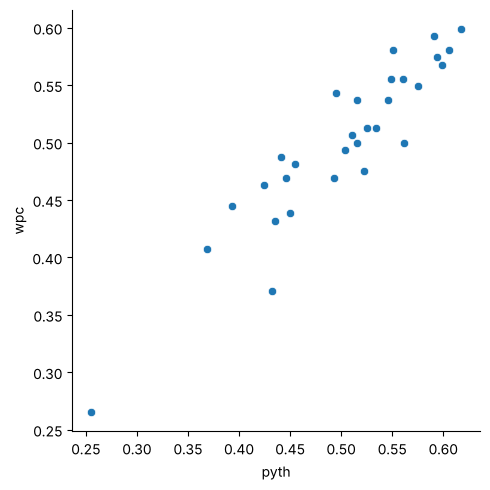

In [11]:
sns.relplot(x="pyth",y="wpc",data=MLB18)

In [12]:
pyth_lm = smf.ols(formula='wpc ~ pyth',data=MLB18).fit()
pyth_lm.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    wpc   R-squared:                       0.857
Model:                            OLS   Adj. R-squared:                  0.852
Method:                 Least Squares   F-statistic:                     167.8
Date:                Sat, 31 Oct 2026   Prob (F-statistic):           2.40e-13
Time:                        17:07:04   Log-Likelihood:                 65.962
No. Observations:                  30   AIC:                            -127.9
Df Residuals:                      28   BIC:                            -125.1
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.0843      0.032      2.596      0.015       0.018       0.151
pyth           0.8278      0.064     12.954      0.000       0.697       0.959
==============================================================================
Omnibus:                        1.867   Durbin-Watson:                   2.179
Prob(Omnibus):                  0.393   Jarque-Bera (JB):                1.048
Skew:                          -0.449   Prob(JB):                        0.592
Kurtosis:                       3.178   Cond. No.                         15.8
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""